In [24]:
import os
import tensorflow as tf

print(os.listdir("../data/raw"))
print(tf.__version__)

['Intel_Image_Classification']
2.22.0-rc0


In [25]:
train_dir="../data/raw/Intel_Image_Classification/seg_train_test/seg_train"

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(150,150),
    batch_size=32,
)


val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(150,150),
    batch_size=32,
)


print("Categories: ", train_ds.class_names)

Found 14335 files belonging to 6 classes.
Using 11468 files for training.
Found 14335 files belonging to 6 classes.
Using 2867 files for validation.
Categories:  ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [26]:
images, labels = next(iter(train_ds))

print("Shape:", images.shape)
print("labels:", labels.shape)

label_number = int(labels[0].numpy())
print("Label_number:",label_number)
print("Class name:", train_ds.class_names[label_number])

Shape: (32, 150, 150, 3)
labels: (32,)
Label_number: 3
Class name: mountain


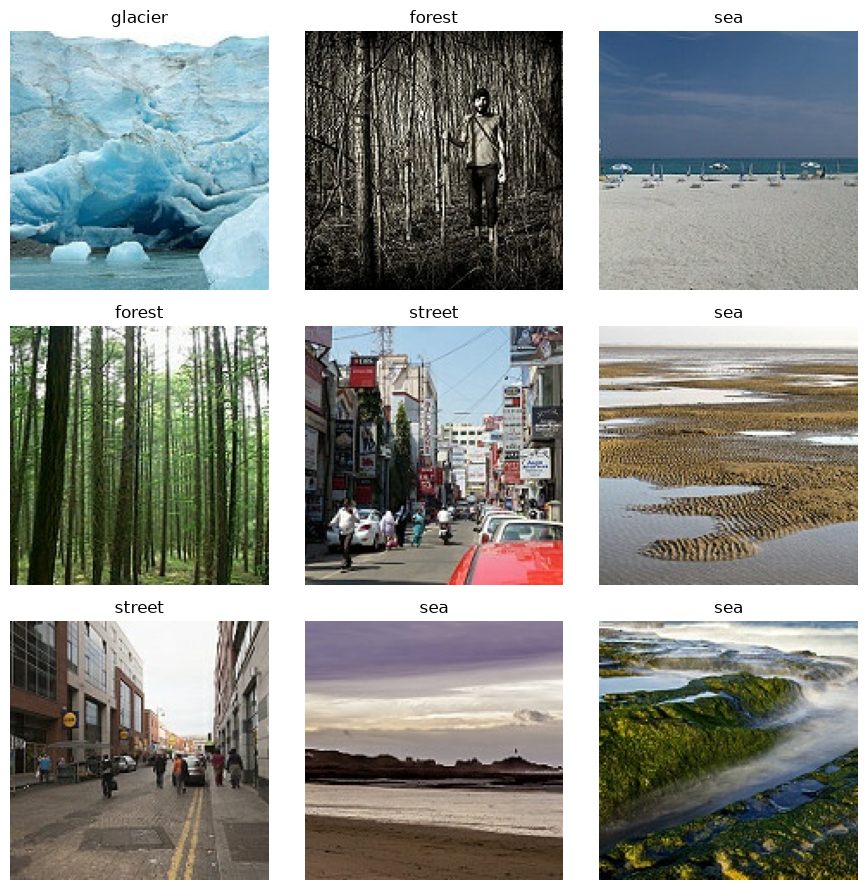

In [32]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_ds))
class_names = train_ds.class_names

plt.figure(figsize=(9, 9))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))

    label_number = int(labels[i].numpy())
    plt.title(class_names[label_number])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [34]:
from pathlib import Path

train_path = Path(train_dir)

for class_dir in sorted(train_path.iterdir()):
        image_count = len(list(class_dir.glob("*.jpg")))
        print(f"{class_dir.name}: {image_count} images")

buildings: 0 images
forest: 2674 images
glacier: 2957 images
mountain: 3037 images
sea: 2784 images
street: 2883 images
